# 05 Report figures

Publication quality figures for the thesis: no training, no ClearML. Every figure is saved twice, as a
vector PDF (`\includegraphics` in LaTeX) and a PNG preview, under `OUT_DIR`, one file per figure so each
can be dropped into Overleaf individually.

Pulls from the repaired keypoints (`keypoints_interp`) and the same `dataset.py` used for training, so
what is shown here is exactly what the models see.

In [1]:
import os
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO = os.environ.get("BADMINTON_REPO", "/workspace/badminton-honours-project")
DATA = os.environ.get("BADMINTON_DATA", "/workspace/data")
OUT_DIR = os.environ.get("BADMINTON_REPORT_FIGS", "/workspace/outputs/report_figures")
sys.path.insert(0, REPO)
import dataset as ds

os.makedirs(OUT_DIR, exist_ok=True)
KEYPOINTS = f"{DATA}/keypoints_interp"
SEED = 0
R_WRIST, L_HIP, R_HIP = 10, 11, 12

plt.rcParams.update({
    "figure.dpi": 140, "savefig.dpi": 300, "font.size": 10, "font.family": "serif",
    "axes.spines.top": False, "axes.spines.right": False,
})
REAL_COLOUR, AUG_COLOUR = "#1a1a1a", "#c44e52"


def save(fig, name):
    fig.savefig(f"{OUT_DIR}/{name}.pdf", bbox_inches="tight")
    fig.savefig(f"{OUT_DIR}/{name}.png", bbox_inches="tight")
    plt.show()
    print(f"saved {name}.pdf / .png")

In [2]:
manifest = ds.load_filtered_manifest(f"{DATA}/split_manifest.csv", f"{DATA}/extraction_log.csv",
                                     f"{DATA}/keypoints_interp_log.csv", min_native_frames=5)
class_names = sorted(manifest["class_name"].unique())
label = {c: c.split("_", 1)[1] for c in class_names}
n_native = pd.read_csv(f"{DATA}/keypoints_interp_log.csv").set_index("filepath")["n_native"]
rng = np.random.RandomState(SEED)


def load(row):
    stem = os.path.splitext(os.path.basename(row["filepath"]))[0]
    return np.load(f"{KEYPOINTS}/{row['class_name']}/{stem}.npy").astype(np.float32)


def normalise(clip):
    return ds.normalise_body(clip)[..., :2]


def draw_skeleton(ax, xy, colour, lw=1.4, ms=10, alpha=1.0):
    for a, b in ds.COCO_SKELETON:
        ax.plot(xy[[a, b], 0], xy[[a, b], 1], color=colour, lw=lw, alpha=alpha, solid_capstyle="round")
    ax.scatter(xy[:, 0], xy[:, 1], color=colour, s=ms, alpha=alpha, zorder=3, linewidths=0)

manual review: dropped 4 clips
short clip rule: dropped 4 train clips with fewer than 5 real frames
7810 clips remain (train 6247, test 782, val 781)


## 1. Class samples

One training clip per class, hip centred and scaled by body height, five frames overlaid from early
(light) to late (dark), with the right wrist path traced.

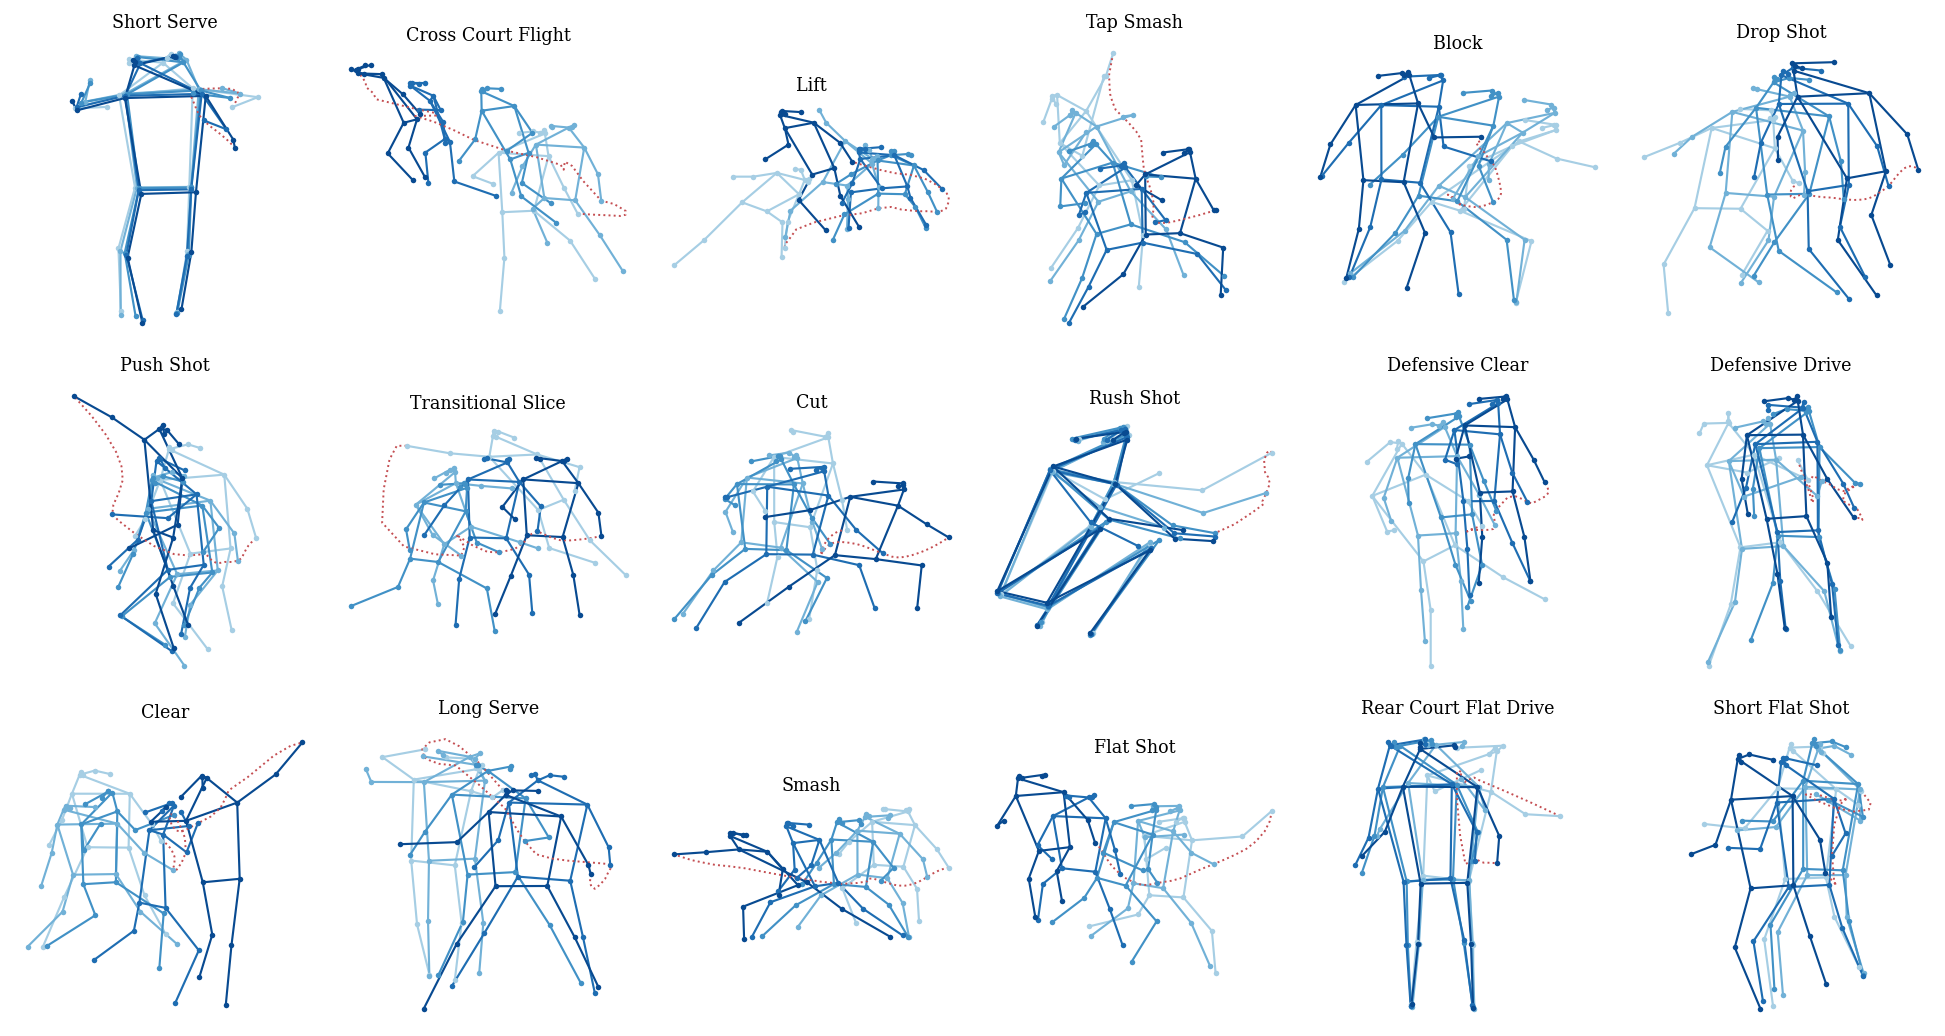

saved 01_class_samples.pdf / .png


In [3]:
fig, axes = plt.subplots(3, 6, figsize=(14, 7.5))
cmap = plt.get_cmap("Blues")
for ax, c in zip(axes.flat, class_names):
    pool = manifest[(manifest["class_name"] == c) & (manifest["split"] == "train") &
                    (manifest["filepath"].map(n_native) >= 15)]
    pool = pool if len(pool) else manifest[manifest["class_name"] == c]
    row = pool.iloc[rng.randint(len(pool))]
    xy = normalise(load(row))
    for i, t in enumerate(np.linspace(0, 29, 5).astype(int)):
        draw_skeleton(ax, xy[t], cmap(0.35 + 0.55 * i / 4), lw=1.1, ms=8)
    ax.plot(xy[:, R_WRIST, 0], xy[:, R_WRIST, 1], color="#c44e52", lw=1, ls=":", zorder=2)
    ax.set_title(label[c], fontsize=9)
    ax.set_aspect("equal")
    ax.invert_yaxis()
    ax.axis("off")
fig.tight_layout()
save(fig, "01_class_samples")

## 2. Class distribution and clip length

Two compact figures, split out separately so either can be placed on its own in the report.

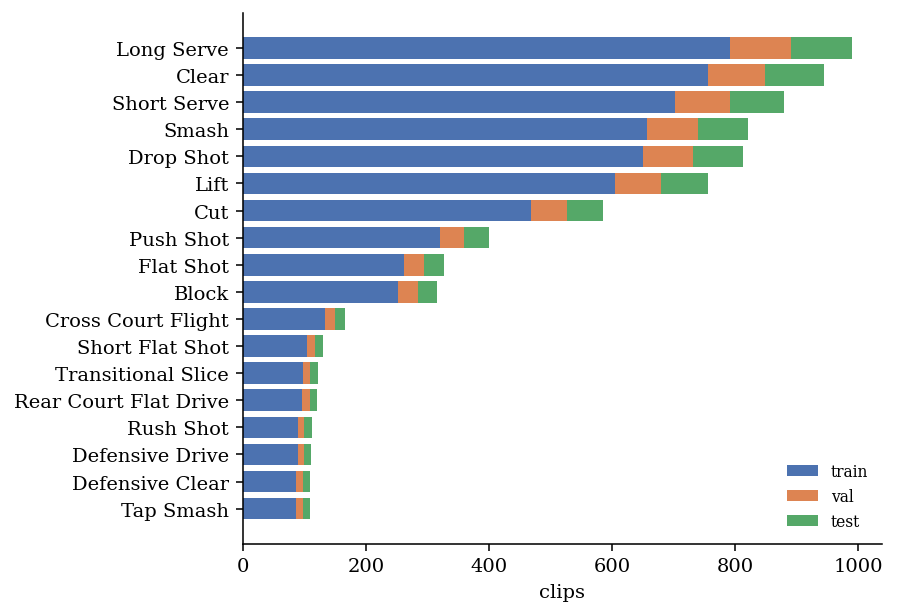

saved 02_class_distribution.pdf / .png


In [4]:
counts = pd.crosstab(manifest["class_name"], manifest["split"])[["train", "val", "test"]]
order = counts.sum(axis=1).sort_values().index
fig, ax = plt.subplots(figsize=(6.5, 4.5))
left = np.zeros(len(order))
colours = {"train": "#4c72b0", "val": "#dd8452", "test": "#55a868"}
for split in ["train", "val", "test"]:
    ax.barh([label[c] for c in order], counts.loc[order, split], left=left, color=colours[split], label=split)
    left += counts.loc[order, split].to_numpy()
ax.set_xlabel("clips")
ax.legend(frameon=False, loc="lower right", fontsize=8)
fig.tight_layout()
save(fig, "02_class_distribution")

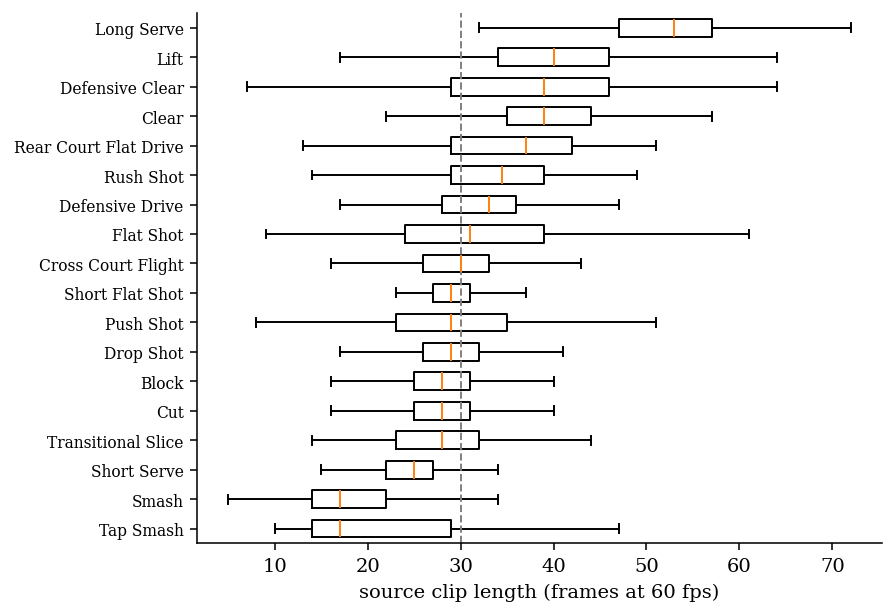

saved 03_clip_length.pdf / .png


In [5]:
log = pd.read_csv(f"{DATA}/extraction_log.csv")
merged = manifest.merge(log[["filepath", "num_frames_total"]], on="filepath")
length_order = merged.groupby("class_name")["num_frames_total"].median().sort_values().index
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.boxplot([merged.loc[merged["class_name"] == c, "num_frames_total"] for c in length_order],
           vert=False, showfliers=False, widths=0.6)
ax.set_yticks(range(1, len(length_order) + 1), [label[c] for c in length_order], fontsize=8)
ax.axvline(30, color="grey", ls="--", lw=1)
ax.set_xlabel("source clip length (frames at 60 fps)")
fig.tight_layout()
save(fig, "03_clip_length")

## 3. Resampling repair

One short clip's right wrist before (duplicated frames, then smoothed) and after (smoothed at the native
rate, then interpolated) the repair, against the true frame positions.

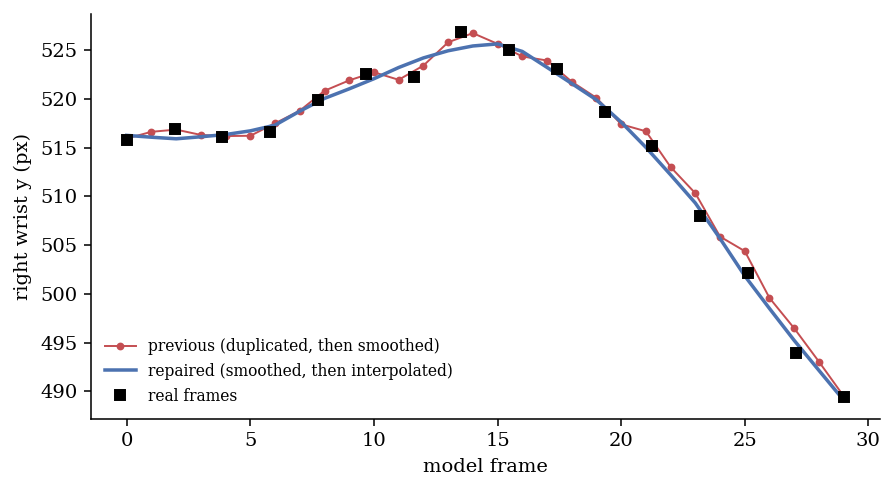

saved 04_resampling_repair.pdf / .png


In [6]:
repair = pd.read_csv(f"{DATA}/keypoints_interp_log.csv")
merged_r = manifest.merge(repair[["filepath", "n_native", "mode"]], on="filepath")
candidates = merged_r[(merged_r["mode"] == "interpolated") & merged_r["n_native"].between(12, 16)]
example = candidates.sort_values("filepath").iloc[len(candidates) // 3]

def load_named(folder, row):
    stem = os.path.splitext(os.path.basename(row["filepath"]))[0]
    return np.load(f"{DATA}/{folder}/{row['class_name']}/{stem}.npy")

raw, old, new = (load_named(f, example) for f in ["keypoints_raw", "keypoints_smoothed", "keypoints_interp"])
n = int(example["n_native"])
slot_of = np.linspace(0, n - 1, 30).round().astype(int)
native = raw[[int(np.argmax(slot_of == k)) for k in range(n)]]
native_t = np.arange(n) * 29 / (n - 1)

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(range(30), old[:, R_WRIST, 1], "o-", ms=3, lw=1, color="#c44e52", label="previous (duplicated, then smoothed)")
ax.plot(range(30), new[:, R_WRIST, 1], "-", lw=1.8, color="#4c72b0", label="repaired (smoothed, then interpolated)")
ax.plot(native_t, native[:, R_WRIST, 1], "ks", ms=5, label="real frames")
ax.set_xlabel("model frame")
ax.set_ylabel("right wrist y (px)")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
save(fig, "04_resampling_repair")

## 4. Augmentation: real vs augmented, overlaid frames

One clip per technique, five frames overlaid (early to late, light to dark), real in black and one
augmented draw in red, matching the pair-of-rows style used for the earlier failed run so the comparison
stays visually consistent across notebooks.

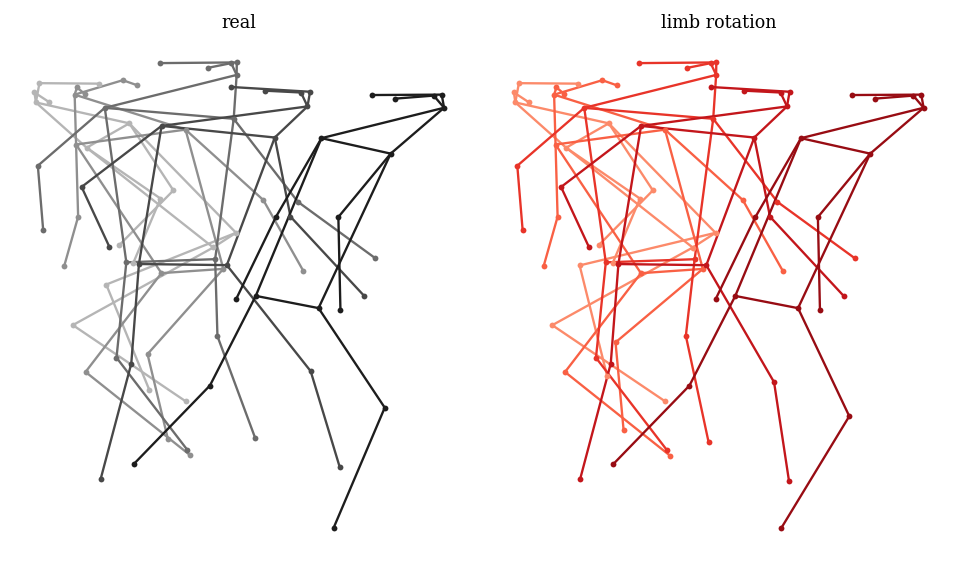

saved 05_augmentation_limb_rotation.pdf / .png


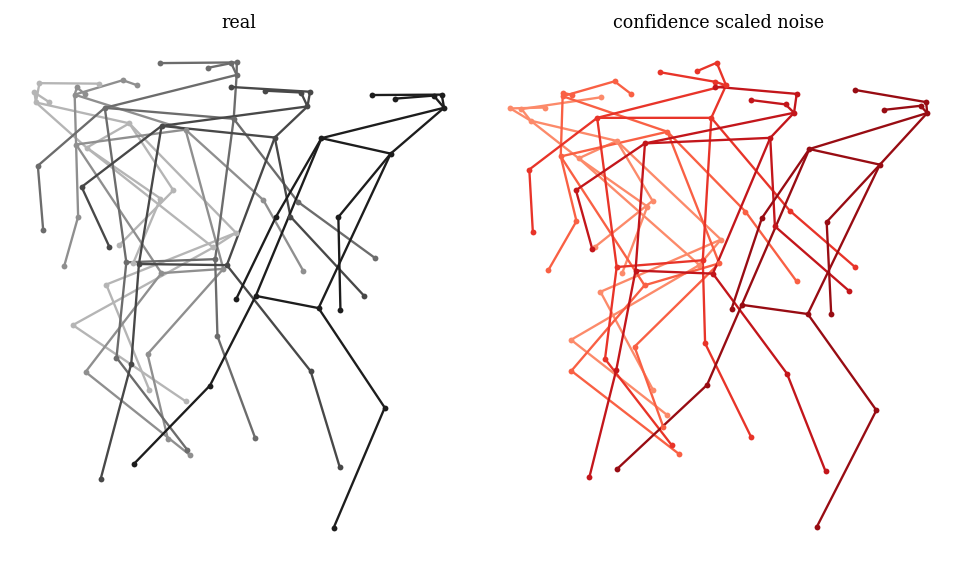

saved 05_augmentation_confidence_scaled_noise.pdf / .png


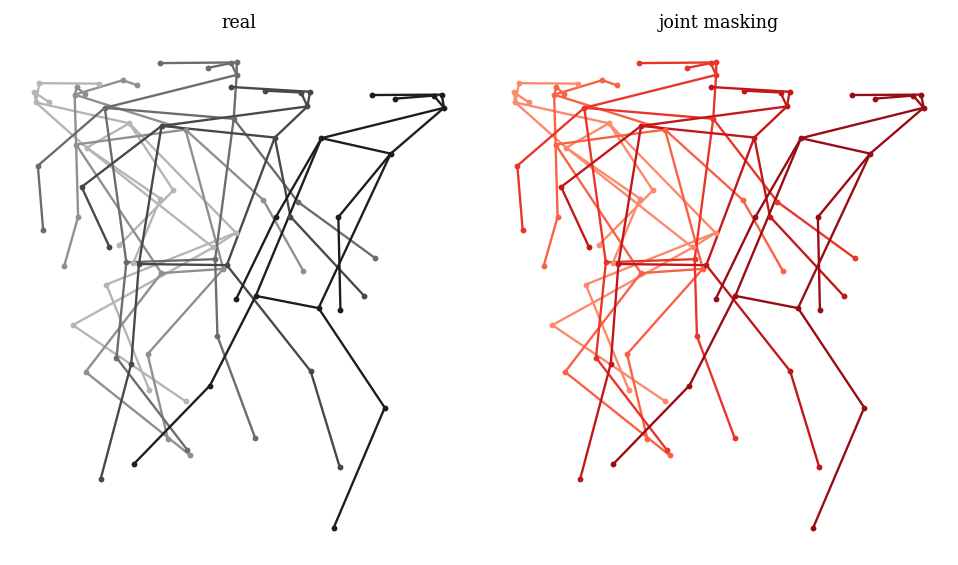

saved 05_augmentation_joint_masking.pdf / .png


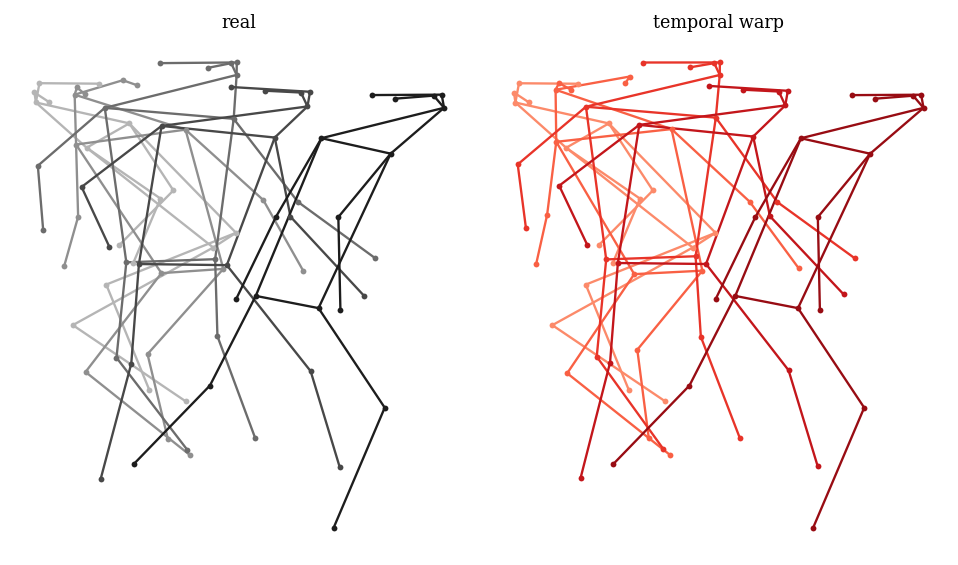

saved 05_augmentation_temporal_warp.pdf / .png


In [7]:
pool = manifest[(manifest["class_name"].str.endswith("Smash")) & (manifest["split"] == "train") &
                (manifest["filepath"].map(n_native) >= 20)]
base_row = pool.iloc[rng.randint(len(pool))]
base = load(base_row)

AUGS = [("limb rotation", ds.aug_limb_rotation), ("confidence scaled noise", ds.aug_confidence_scaled_noise),
        ("joint masking", ds.aug_joint_masking), ("temporal warp", ds.aug_temporal_warp)]
frames = np.linspace(0, 29, 5).astype(int)
cmap_real = plt.get_cmap("Greys")
cmap_aug = plt.get_cmap("Reds")

for name, fn in AUGS:
    np.random.seed(SEED)
    out = fn(base.copy(), p=1.0)
    real_xy, aug_xy = normalise(base), normalise(out)
    fig, axes = plt.subplots(1, 2, figsize=(7, 4))
    for ax, xy, cmap in zip(axes, [real_xy, aug_xy], [cmap_real, cmap_aug]):
        for i, t in enumerate(frames):
            draw_skeleton(ax, xy[t], cmap(0.4 + 0.5 * i / 4), lw=1.2, ms=9)
        ax.set_aspect("equal")
        ax.invert_yaxis()
        ax.axis("off")
    axes[0].set_title("real", fontsize=9)
    axes[1].set_title(name, fontsize=9)
    fig.tight_layout()
    save(fig, f"05_augmentation_{name.replace(' ', '_')}")

## 5. Augmentation: real vs augmented, frame by frame

The paired-row layout: real skeleton (black) on top, one augmented draw (red) below, at six time steps
across the clip. Produced for two clips so the report can show more than one example.

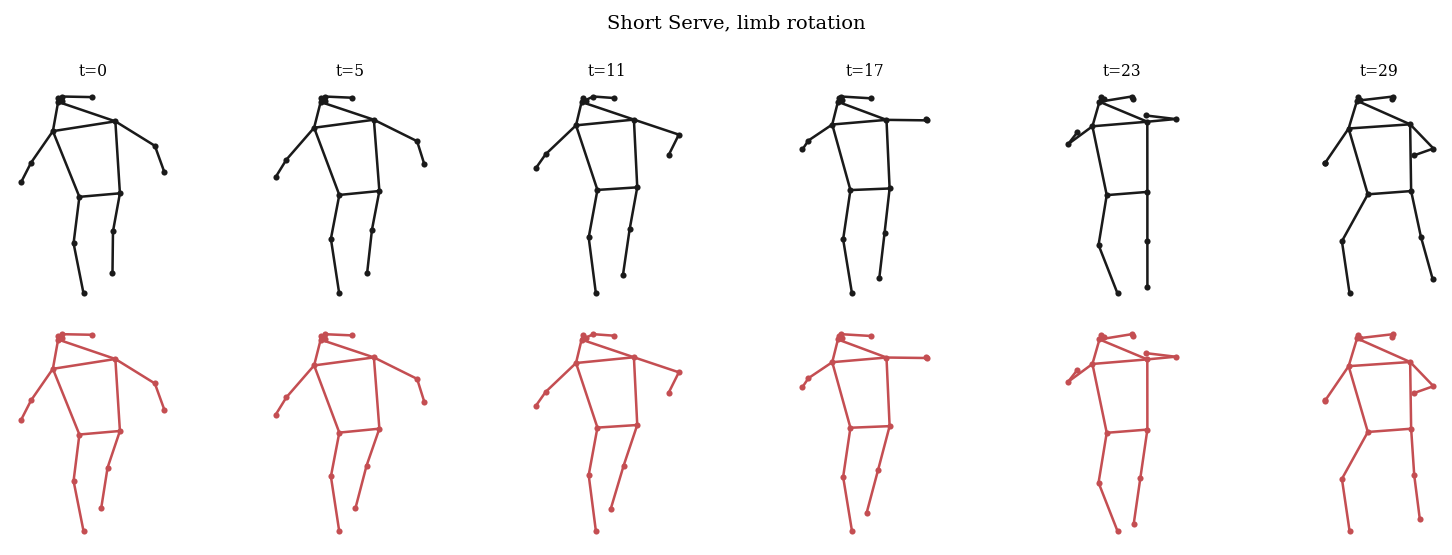

saved 06_paired_clip1_limb_rotation.pdf / .png


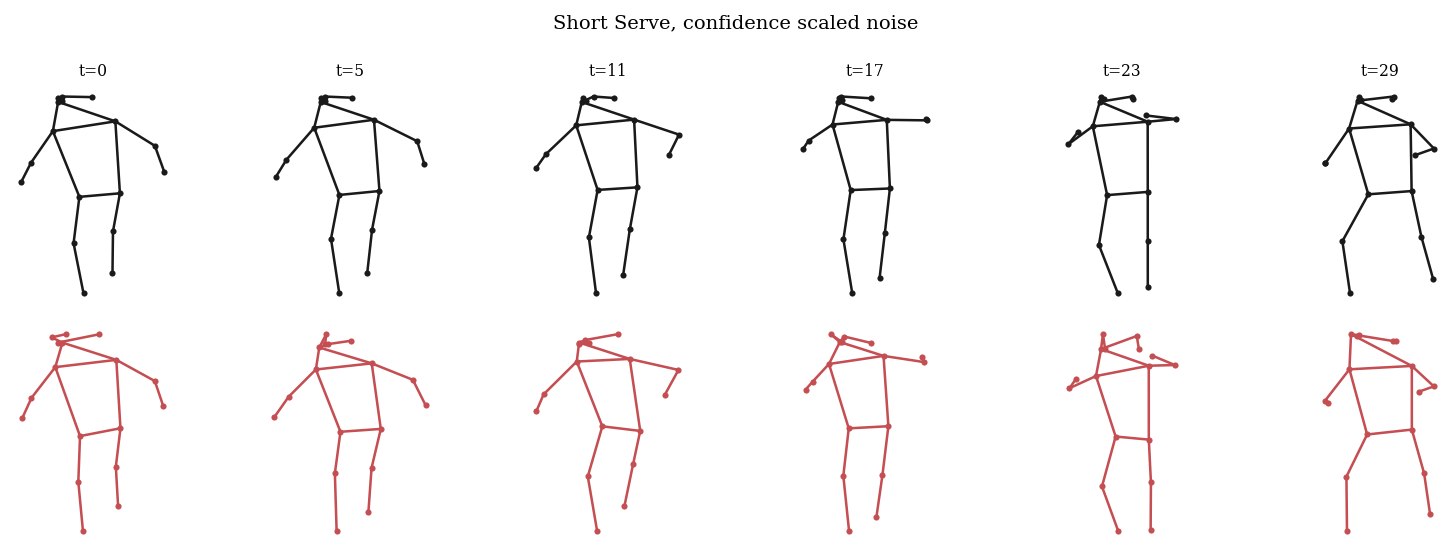

saved 06_paired_clip1_confidence_scaled_noise.pdf / .png


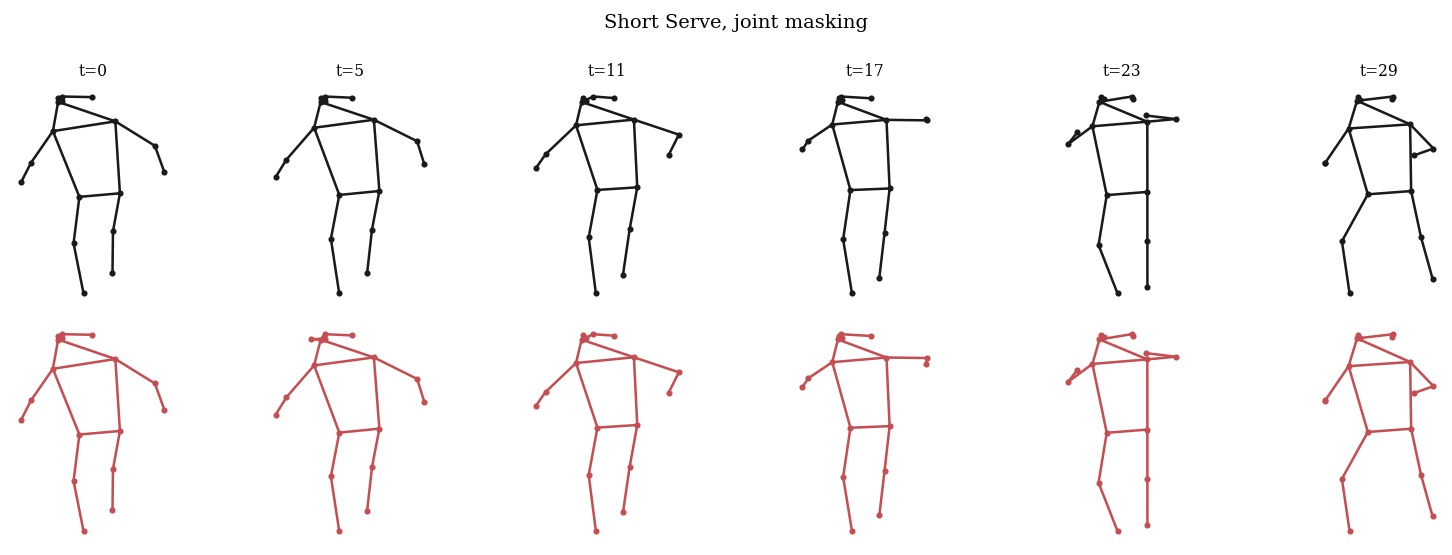

saved 06_paired_clip1_joint_masking.pdf / .png


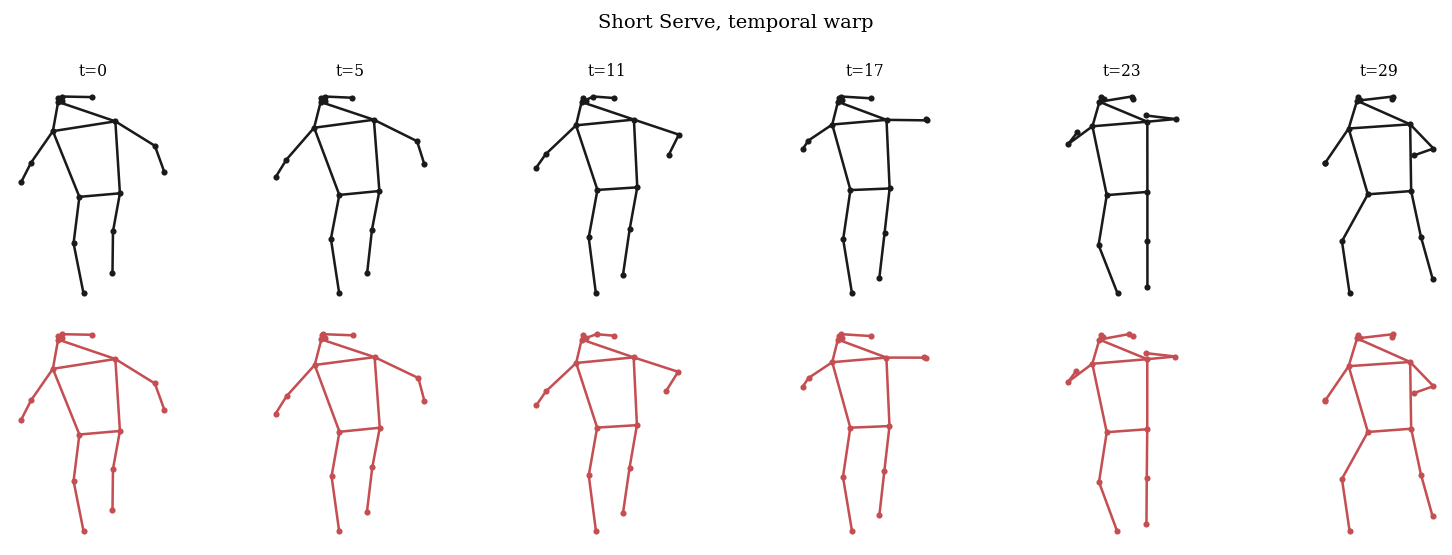

saved 06_paired_clip1_temporal_warp.pdf / .png


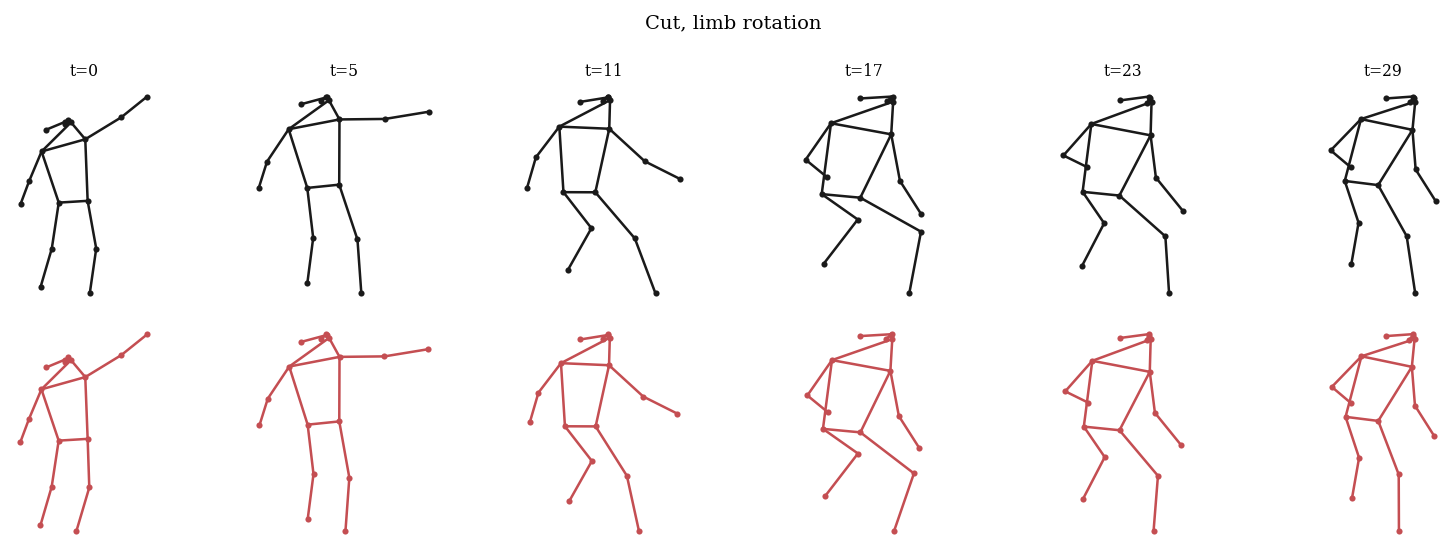

saved 06_paired_clip2_limb_rotation.pdf / .png


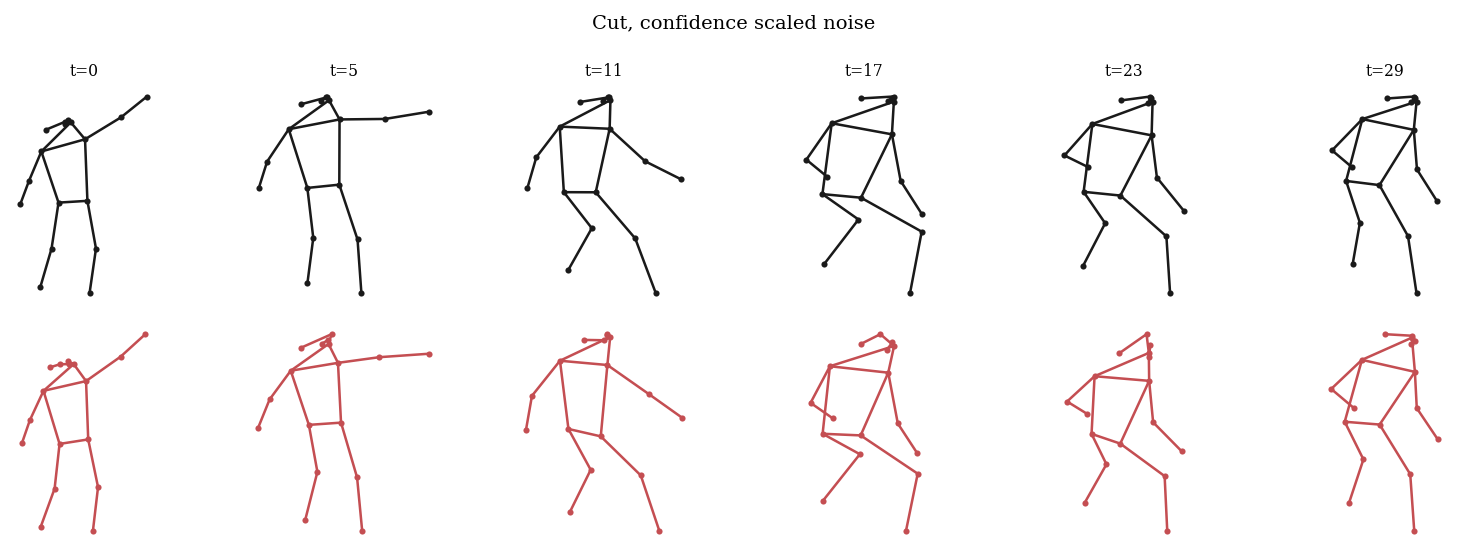

saved 06_paired_clip2_confidence_scaled_noise.pdf / .png


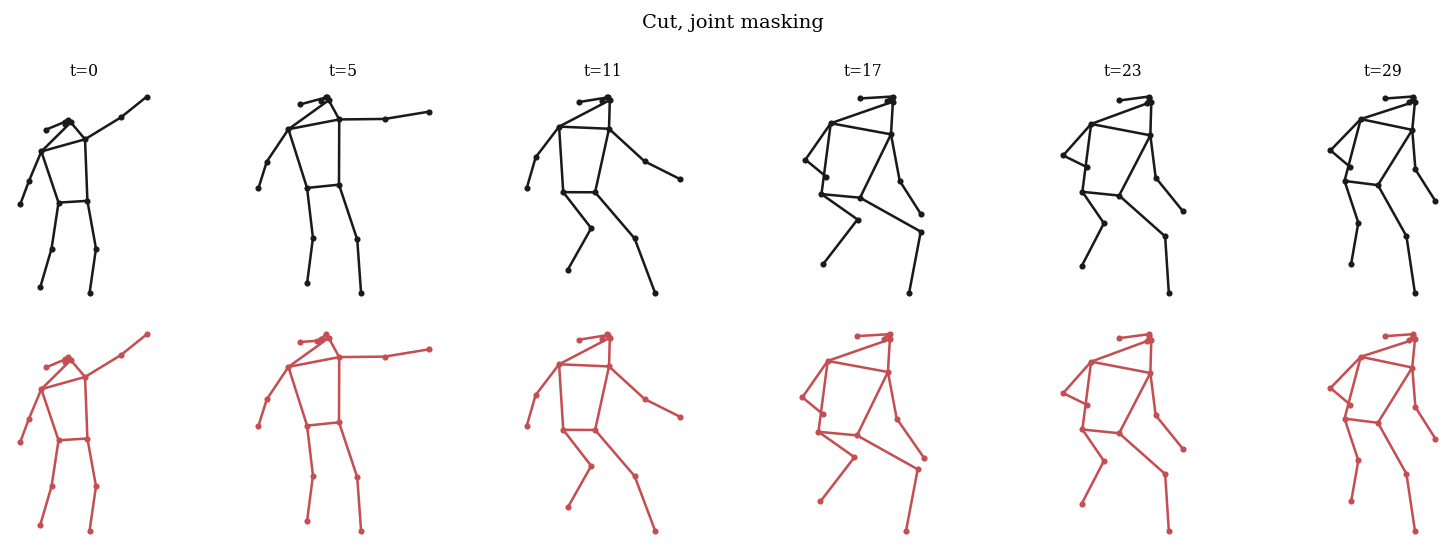

saved 06_paired_clip2_joint_masking.pdf / .png


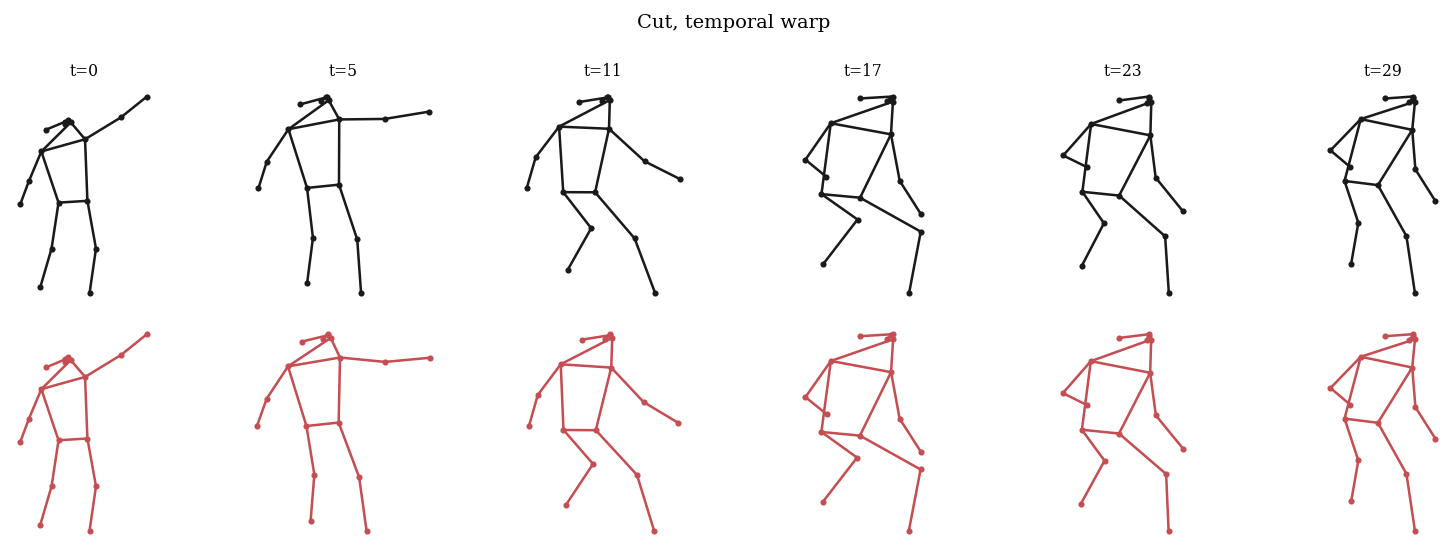

saved 06_paired_clip2_temporal_warp.pdf / .png


In [8]:
def paired_rows_figure(clip, fn, title):
    np.random.seed(SEED)
    out = fn(clip.copy(), p=1.0)
    real_xy, aug_xy = normalise(clip), normalise(out)
    steps = [0, 5, 11, 17, 23, 29]
    fig, axes = plt.subplots(2, len(steps), figsize=(1.9 * len(steps), 4))
    for col, t in enumerate(steps):
        draw_skeleton(axes[0, col], real_xy[t], REAL_COLOUR, lw=1.3, ms=10)
        draw_skeleton(axes[1, col], aug_xy[t], AUG_COLOUR, lw=1.3, ms=10)
        axes[0, col].set_title(f"t={t}", fontsize=8)
        for row in (0, 1):
            axes[row, col].set_aspect("equal")
            axes[row, col].invert_yaxis()
            axes[row, col].axis("off")
    fig.suptitle(title, fontsize=10)
    fig.tight_layout()
    return fig


clip_pool = manifest[(manifest["split"] == "train") & (manifest["filepath"].map(n_native) >= 25)]
example_clips = clip_pool.sample(2, random_state=SEED)
for i, (_, row) in enumerate(example_clips.iterrows(), start=1):
    clip = load(row)
    for name, fn in AUGS:
        fig = paired_rows_figure(clip, fn, f"{label[row['class_name']]}, {name}")
        save(fig, f"06_paired_clip{i}_{name.replace(' ', '_')}")

## 6. Augmentation: full advanced bundle applied together

What a real training draw actually looks like: all four techniques applied in sequence with their normal
probabilities, four independent draws of the same clip.

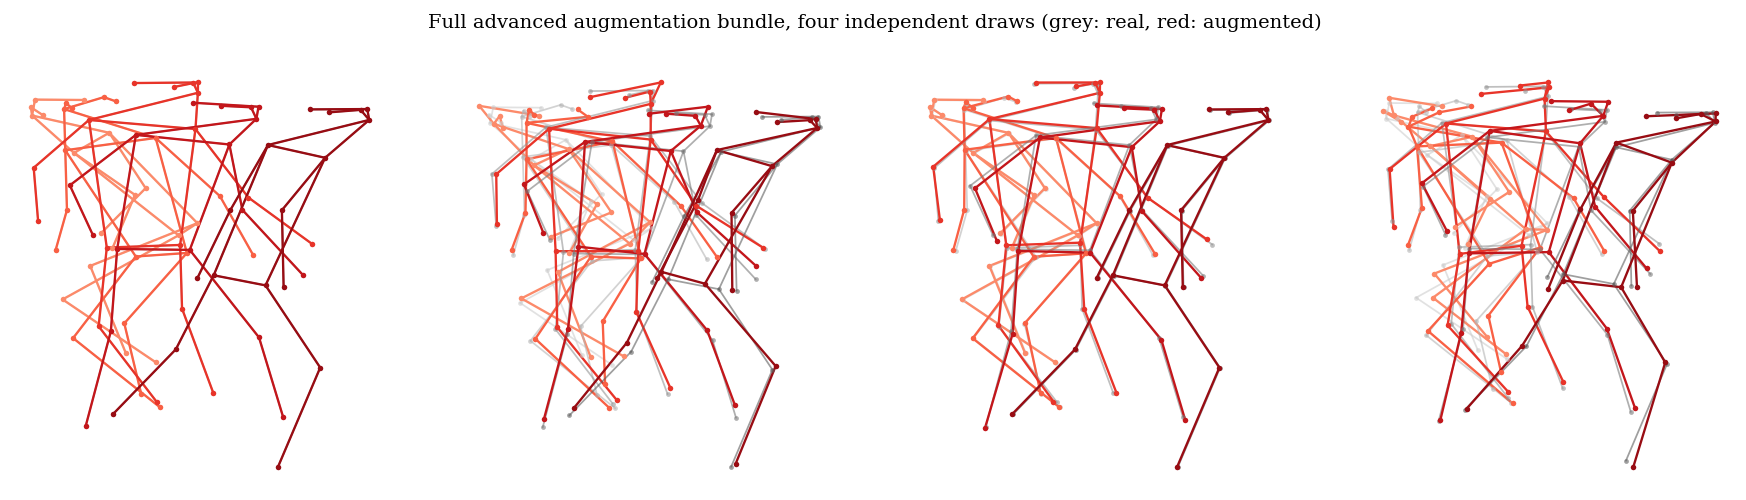

saved 07_full_bundle.pdf / .png


In [9]:
np.random.seed(SEED)
fig, axes = plt.subplots(1, 4, figsize=(13, 3.6))
real_xy = normalise(base)
for ax in axes:
    out = base.copy()
    for fn in ds.ADVANCED_AUGMENTATIONS:
        out = fn(out)
    aug_xy = normalise(out)
    for i, t in enumerate(frames):
        draw_skeleton(ax, real_xy[t], cmap_real(0.3 + 0.4 * i / 4), lw=0.9, ms=6, alpha=0.6)
        draw_skeleton(ax, aug_xy[t], cmap_aug(0.4 + 0.5 * i / 4), lw=1.2, ms=8)
    ax.set_aspect("equal")
    ax.invert_yaxis()
    ax.axis("off")
fig.suptitle("Full advanced augmentation bundle, four independent draws (grey: real, red: augmented)", fontsize=10)
fig.tight_layout()
save(fig, "07_full_bundle")

## 7. Normalisation: pixel vs body

40 training clips at one frame, in pixel coordinates and after hip centring and body height scaling.

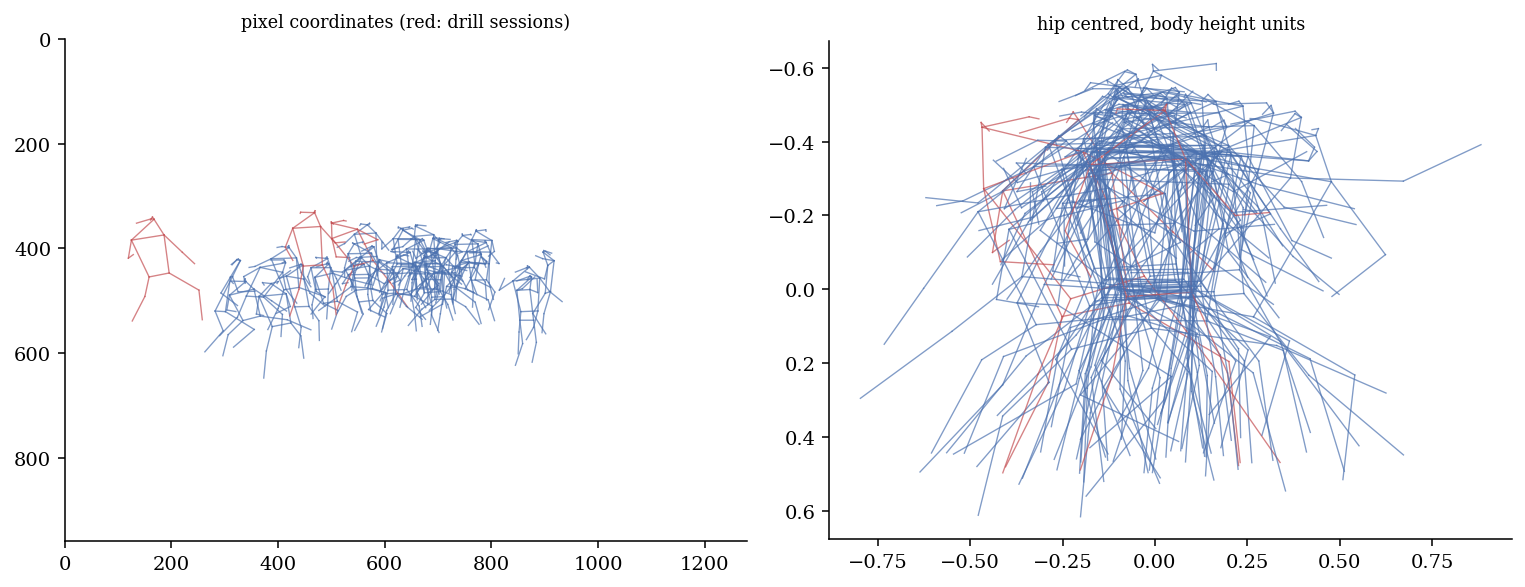

saved 08_normalisation.pdf / .png


In [10]:
picks = manifest[manifest["split"] == "train"].sample(40, random_state=SEED)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
for _, r in picks.iterrows():
    kp = load(r)
    drill = "2023-05-02" in r["filepath"]
    colour = "#c44e52" if drill else "#4c72b0"
    body = ds.normalise_body(kp)
    t = 15
    for ax, arr in [(axes[0], kp), (axes[1], body)]:
        for a, b in ds.COCO_SKELETON:
            ax.plot(arr[t, [a, b], 0], arr[t, [a, b], 1], color=colour, lw=0.7, alpha=0.7)
axes[0].set_xlim(0, 1280)
axes[0].set_ylim(960, 0)
axes[0].set_title("pixel coordinates (red: drill sessions)", fontsize=9)
axes[1].invert_yaxis()
axes[1].set_aspect("equal")
axes[1].set_title("hip centred, body height units", fontsize=9)
fig.tight_layout()
save(fig, "08_normalisation")

In [11]:
print("all figures saved to", OUT_DIR)
sorted(f for f in os.listdir(OUT_DIR) if f.endswith(".pdf"))

all figures saved to /workspace/outputs/report_figures


['01_class_samples.pdf',
 '02_class_distribution.pdf',
 '03_clip_length.pdf',
 '04_resampling_repair.pdf',
 '05_augmentation_confidence_scaled_noise.pdf',
 '05_augmentation_joint_masking.pdf',
 '05_augmentation_limb_rotation.pdf',
 '05_augmentation_temporal_warp.pdf',
 '06_paired_clip1_confidence_scaled_noise.pdf',
 '06_paired_clip1_joint_masking.pdf',
 '06_paired_clip1_limb_rotation.pdf',
 '06_paired_clip1_temporal_warp.pdf',
 '06_paired_clip2_confidence_scaled_noise.pdf',
 '06_paired_clip2_joint_masking.pdf',
 '06_paired_clip2_limb_rotation.pdf',
 '06_paired_clip2_temporal_warp.pdf',
 '07_full_bundle.pdf',
 '08_normalisation.pdf']

## 8. Augmentation, exaggerated for illustration

The figures above use the true training magnitudes, which are deliberately subtle so augmented clips stay
anatomically plausible (unlike the earlier broken version, visible in the project's failed early attempts).
For clarity in the report, this section reruns the same techniques at 3 to 4x their normal strength.
**These are for illustration only and were never used to train anything.**

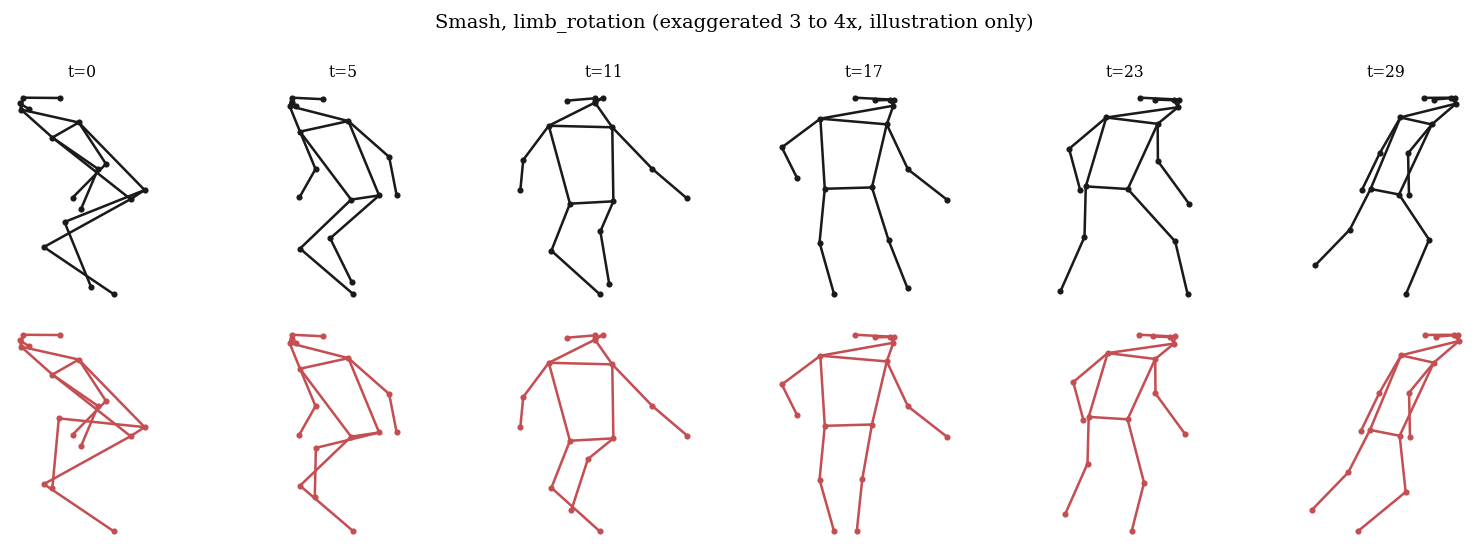

saved 09_exaggerated_limb_rotation.pdf / .png


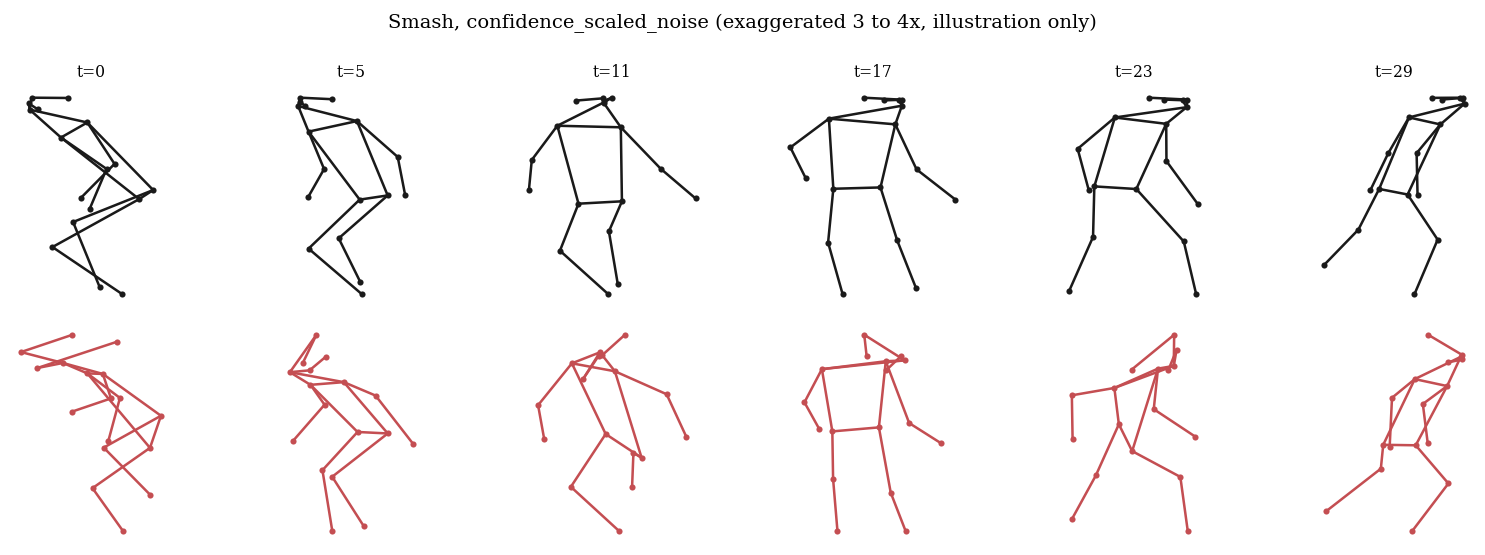

saved 09_exaggerated_confidence_scaled_noise.pdf / .png


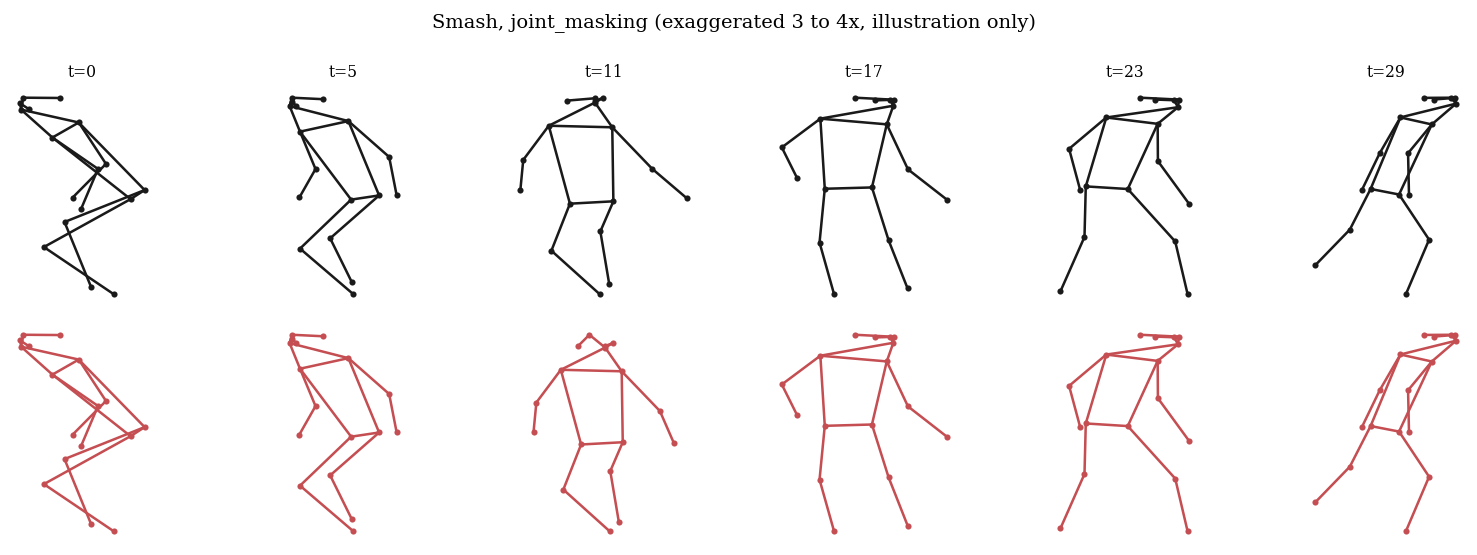

saved 09_exaggerated_joint_masking.pdf / .png


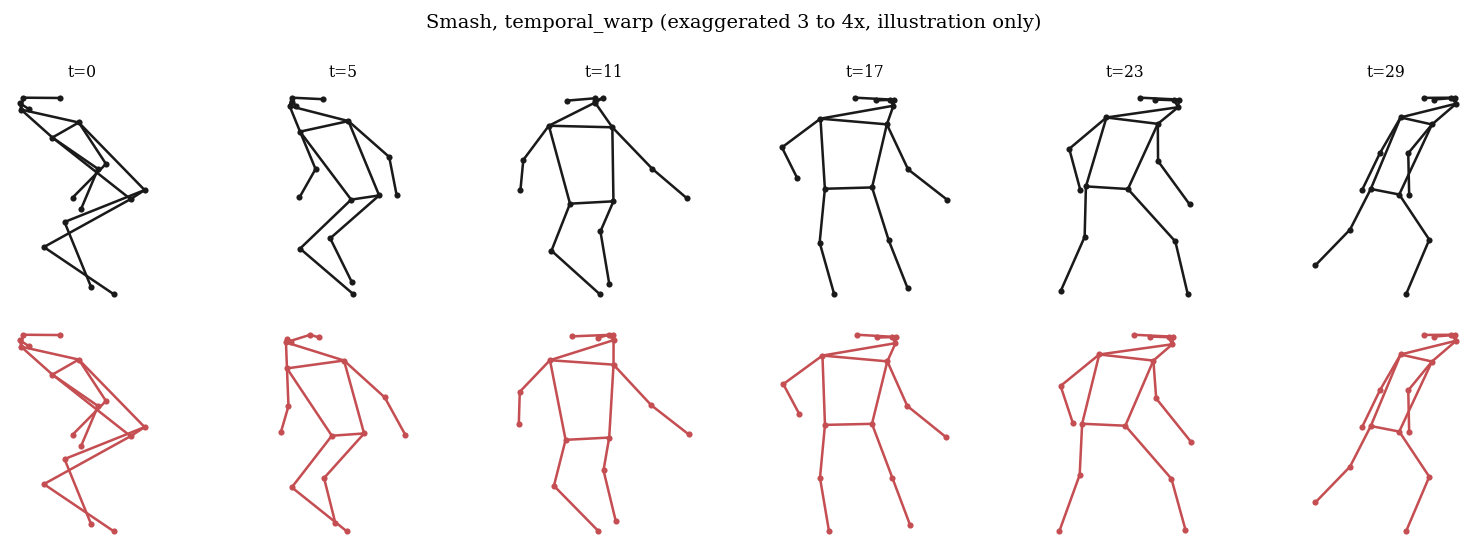

saved 09_exaggerated_temporal_warp.pdf / .png


In [12]:
EXAGGERATED = {
    ds.aug_limb_rotation: dict(max_angle_deg=40.0),
    ds.aug_confidence_scaled_noise: dict(base_frac=0.15),
    ds.aug_joint_masking: dict(max_joints=3, max_span=10),
    ds.aug_temporal_warp: dict(max_warp=0.9),
}

for fn, kwargs in EXAGGERATED.items():
    name = fn.__name__.replace("aug_", "")
    np.random.seed(SEED)
    strong = lambda kp, p=1.0, f=fn, kw=kwargs: f(kp, p=p, **kw)
    fig = paired_rows_figure(base, strong, f"{label[base_row['class_name']]}, {name} (exaggerated 3 to 4x, illustration only)")
    save(fig, f"09_exaggerated_{name}")